# E5 - Denoising the long exposures (Poisson-Gaussian noise, generalized Anscombe transform)

Denoises frames of an E3/E4 run (or E1 event maps) with a Gaussian denoiser in the
variance-stabilised domain of the generalized Anscombe transform (GAT, Mäkitalo & Foi 2013,
as in the [deepinv example](https://deepinv.org/auto_examples/physics/demo_anscombe.html)),
and scores the result without a ground truth. Works offline on any run folder; nothing here
talks to ImSwitch.

**What it does**

1. Removes transients by comparing each pixel with the same pixel in the other frames:
   cosmic rays, and on the EMCCD the bright *and* dark streaks they leave along the readout
   direction. In the 30 min Andor frames these, not shot noise, dominate the frame-to-frame
   variance.
2. Measures the noise model on the run itself, `var = gain * mean + c`, from second
   differences of consecutive frames (cancels fixed pattern and the leaf fading). No E2
   calibration needed. `gain` is ADU per *count*: the conversion gain on the ToupTek; on the
   EMCCD in analog mode conversion gain x EM gain x excess-noise factor (~2), so one count is
   about half a photoelectron there.
3. Checks that the GAT really turns the noise into std 1 at every level.
4. Denoises one frame with several methods and scores each against the neighbouring frames.
5. Denoises every frame and the sum of all frames, checks that ROI means survive, writes TIFFs
   and a summary to `<run>/denoise/`.

**Reading the score.** Frames k-1 and k+1 have noise independent of frame k, so their GAT
average is an unbiased (noisy) target that also cancels a linear drift. The *held-out error*
is the mean squared error of an estimate against the truth, in units of the raw frame's noise
variance: raw ~ 1, perfect = 0, and 1 / error ~ the number of frames you would have to average
for the same quality. "Truth" is each pixel's mean, *fixed pattern included*: a method that
smooths away dark-current non-uniformity scores worse even if the picture looks cleaner.

**Caveats**

- Denoised images are for figures. Rates and photon budgets stay on the raw data (E1-E4
  analysis); section 6 shows whether ROI means survive denoising.
- DRUNet learned natural images; Noise2Noise learns this run. Look at the residual images:
  leaf edges or dots in them are signal a method removed.
- On the ToupTek most pixel-scale structure is dark-current non-uniformity, not leaf. A
  denoiser keeps it (it is real); subtract a master dark of the same exposure to remove it.

Needs `torch` and `deepinv` (`pip install deepinv`), `scipy`, and `bm3d` for BM3D. DRUNet
downloads its weights from Hugging Face on first use. A GPU helps: Noise2Noise trains in ~10
min on two CPU cores, about a minute on a GPU. `python test_denoising.py` checks the
analysis on synthetic data.

## 1 Settings

In [2]:
import functools
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import biophoton as bp
import denoising as dn

# RUN_DIR = Path("data/E3_andor_long_exposure/2026-10-27_19-34-50_cress_h2o2")
RUN_DIR = Path("data/E4_touptek_long_exposure/2026-10-24_16-27-50_cress_h2o2")
LABEL = "frame"
MODE = "integrated"          # "photon_counting" for E1: frames are thresholded to events (gain 1)
BINNING = 4                 # sum b x b pixels first; 2 for the ToupTek (9 MP, ~4 counts/px in 30 min)
CROP = None                  # [x, y, w, h] in raw pixels, e.g. [900, 700, 2048, 2048]; None = whole frame
FRAME = None                 # frame the methods are compared on; None = middle of the run
TRANSIENT_SIGMA = 5.0
TRANSIENT_DILATE = None      # (rows, cols) grown around each hit; None = (1, 15) Andor, (3, 3) otherwise
NOISY_PIXEL_RATIO = 3.0      # leave out pixels whose temporal variance exceeds the model this many times
METHODS = ["bm3d", "drunet", "drunet_no_gat", "noise2noise"]   # any subset; "blur" is a naive baseline
N2N_STEPS = 1500             # Noise2Noise training steps
DEVICE = None                # None = cuda if available, else cpu
DENOISE_ALL = True           # section 6: every frame with the best single-frame method
                             # (minutes per frame for a full 9 MP ToupTek frame on a CPU)

cfg = bp.load_config(RUN_DIR)
detector = cfg.get("detector", "")
if TRANSIENT_DILATE is None:
    TRANSIENT_DILATE = (1, 15) if "andor" in detector.lower() else (3, 3)
out = dn.out_dir(RUN_DIR)
print(cfg.get("title"), "|", detector)
print("camera:", cfg.get("camera_readback"))
print("output:", out)

E4 - ToupTek, long exposures over time | WidefieldCamera
camera: {'exposure_mode': 'manual', 'pixel_format': 'mono16', 'conversion_gain': 'HCG', 'low_noise': True, 'gain': 23.0, 'blacklevel': 1000, 'target_temperature': -30.0}
output: data/E4_touptek_long_exposure/2026-10-24_16-27-50_cress_h2o2/denoise


## 2 Load, transients

Photon-counting runs are thresholded per raw frame (`bp.photon_events`) and binned afterwards;
their event counts are already Poisson with gain 1, so no transient removal or noise fit.

24 frames of 750 x 748 px, exposure 1800 s, comparing on frame 12
transients: 0.77% of pixel-frames, saturated pixels: 1.39%


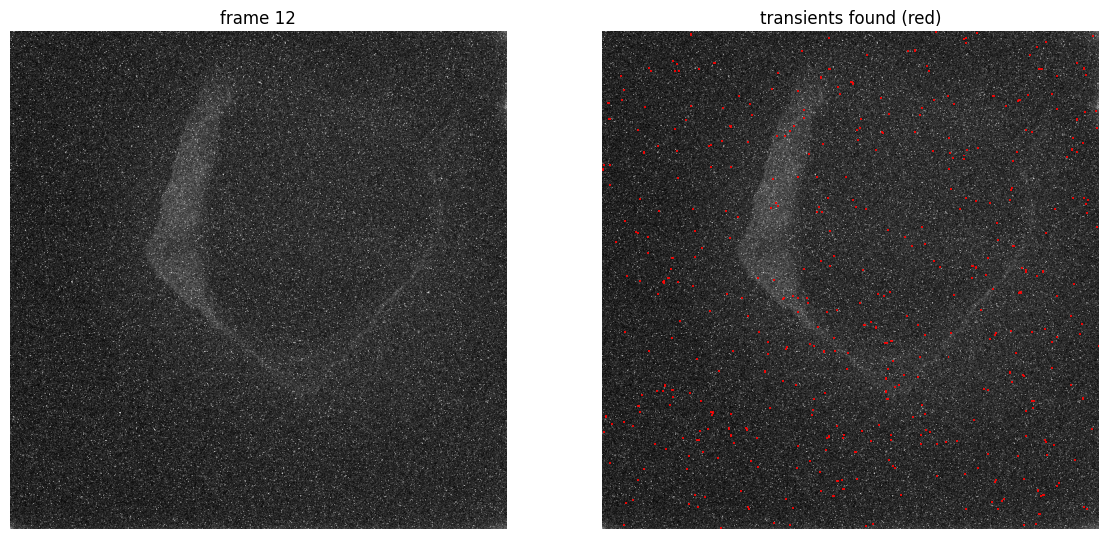

In [3]:
if MODE == "photon_counting":
    raw, frames, _ = dn.load_stack(RUN_DIR, LABEL, crop=CROP)
    stack = dn.bin_image(dn.event_stack(raw, cfg.get("analysis", {}).get("nsigma", 5.0)), BINNING)
    saturated, tmask = None, np.zeros(stack.shape, bool)
    del raw
else:
    stack, frames, saturated = dn.load_stack(RUN_DIR, LABEL, binning=BINNING, crop=CROP)
    tmask = dn.transients(stack, TRANSIENT_SIGMA, TRANSIENT_DILATE)

n_frames = len(stack)
k = n_frames // 2 if FRAME is None else FRAME
exposure_s = frames["exposure_ms"] / 1000
t_h = (frames["start_unix"] + frames["end_unix"]) / 2
t_h = (t_h - t_h[0]) / 3600
print(f"{n_frames} frames of {stack.shape[1]} x {stack.shape[2]} px, exposure {np.median(exposure_s):g} s, "
      f"comparing on frame {k}")
print(f"transients: {tmask.mean():.2%} of pixel-frames"
      + (f", saturated pixels: {saturated.mean():.2%}" if saturated is not None else ""))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
lo, hi = np.percentile(stack[k], [1, 99.5])
for ax in axes:
    ax.imshow(stack[k], cmap="gray", vmin=lo, vmax=hi)
    ax.axis("off")
axes[1].imshow(np.ma.masked_where(~tmask[k], tmask[k]), cmap="autumn", alpha=0.9, interpolation="none")
axes[0].set_title(f"frame {k}")
axes[1].set_title("transients found (red)")
fig.tight_layout()
fig.savefig(out / "figures" / "transients.png", dpi=110)
plt.show()

## 3 Noise model from the run

Pixels are binned by the mean of the even frames, mean and variance are taken from the odd
frames (and vice versa), so a pixel's own noise cannot steer its bin. Saturated, hot and
noisy (random-telegraph-like) pixels are left out of everything that follows.

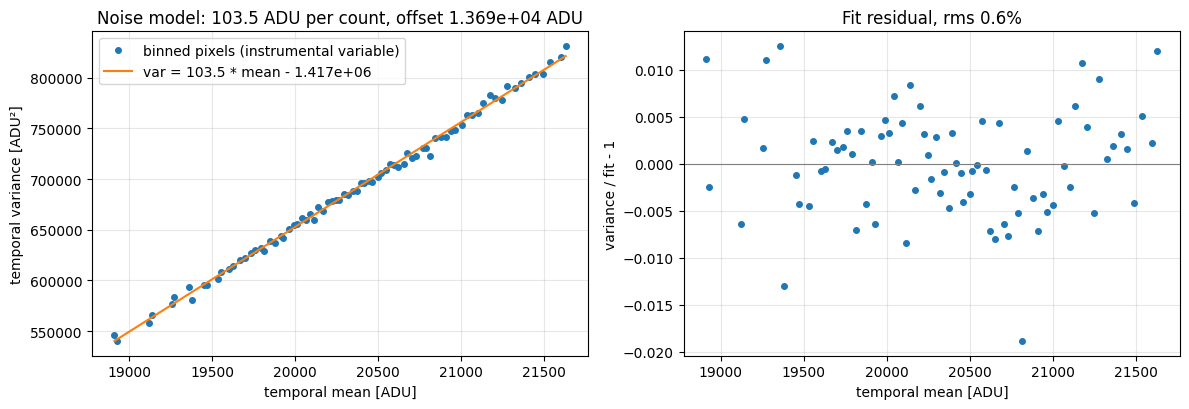

gain 103.5 ADU/count, effective offset 1.369e+04 ADU, fit residual 0.6%
left out: 3.65% of pixels
median 67.2 counts per 4x4 px per frame = 0.00233 counts/raw px/s (leaf + dark + glow)


In [4]:
mask = dn.bad_pixels(stack, tmask, saturated)
if MODE == "photon_counting":
    model = dn.fixed_model(1.0, 0.0)
else:
    model = dn.fit_noise(stack, mask, tmask)
    mask |= dn.noisy_pixels(stack, model, tmask, NOISY_PIXEL_RATIO)
    model = dn.fit_noise(stack, mask, tmask)          # refit without them
    fig = dn.fig_noise_model(model)
    fig.savefig(out / "figures" / "noise_model.png", dpi=110)
    plt.show()

counts = dn.to_counts(dn.clean(stack, tmask), model)
sigma = model["read_noise_counts"]
level = float(np.median(counts[:, ~mask]))
print(f"gain {model['gain_adu_per_count']:.4g} ADU/count, effective offset {model['offset_adu']:.4g} ADU, "
      f"fit residual {model.get('fit_rel_residual_rms', 0):.1%}")
print(f"left out: {mask.mean():.2%} of pixels")
print(f"median {level:.3g} counts per {BINNING}x{BINNING} px per frame "
      f"= {level / BINNING**2 / np.median(exposure_s):.3g} counts/raw px/s (leaf + dark + glow)")
if "andor" in detector.lower() and MODE != "photon_counting":
    print("EMCCD analog: one count ~ 1/2 photoelectron (excess-noise factor 2 folded into the gain)")

## 4 Variance stabilisation

Temporal noise of the GAT frames per level. Within ~5 % of 1 everywhere means the GAT works
and a Gaussian denoiser sees what it was built for. A rise at some levels points at noise the
model does not cover there (missed transients, the leaf changing faster than linearly).

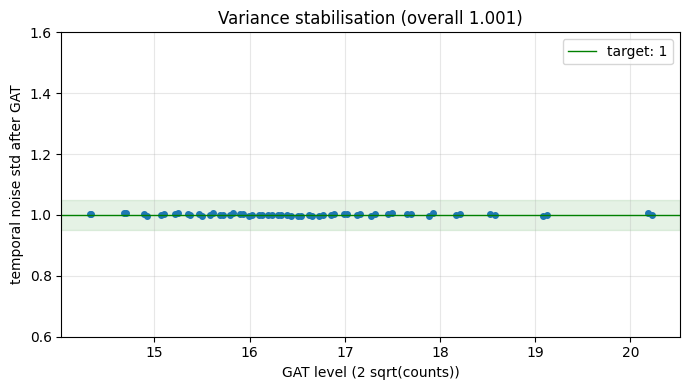

In [5]:
check = dn.stabilisation_check(counts, sigma, mask, tmask)
fig = dn.fig_stabilisation(check)
fig.savefig(out / "figures" / "stabilisation.png", dpi=110)
plt.show()

## 5 Methods on one frame

- **GAT + BM3D / DRUNet / blur**: the deepinv recipe, GAT -> Gaussian denoiser -> inverse GAT.
- **DRUNet, no GAT**: the same network with one global noise level, for comparison.
- **GAT + Noise2Noise**: a small DnCNN trained on pairs of consecutive frames of this run
  (same leaf, independent noise). Frames k-1, k, k+1 are kept out of training so the score
  stays honest.
- **mean of nearby / all frames**: temporal averaging, for scale. It gives up time resolution.

In [6]:
z = dn.gat(counts, sigma)
scaling = dn.gat_scaling(z)
print(f"noise level handed to the denoisers: {1 / scaling[1]:.3f} on a [0, 1] scale"
      + ("  (above ~0.2 DRUNet works outside its training range: bin or sum first)" if 1 / scaling[1] > 0.2 else ""))

get_drunet = functools.lru_cache(None)(lambda: dn.drunet(DEVICE))
train = [i for i in range(n_frames) if abs(i - k) > 1]
n2n = {}

def make_n2n():
    print(f"training Noise2Noise on {len(train)} frames, {N2N_STEPS} steps")
    n2n["net"] = dn.train_noise2noise((z[train] - scaling[0]) / scaling[1], mask=mask,
                                      steps=N2N_STEPS, device=DEVICE)
    return n2n["net"]

def gat_method(make):
    cache = {}
    def f(c, s=sigma, sc=scaling):
        if "d" not in cache:
            cache["d"] = make()
        return dn.denoise_counts(c, cache["d"], s, sc)[0]
    return f

available = {
    "blur": ("GAT + blur 1.5 px", gat_method(lambda: dn.gaussian_blur(1.5))),
    "bm3d": ("GAT + BM3D", gat_method(lambda: dn.bm3d(DEVICE))),
    "drunet": ("GAT + DRUNet", gat_method(get_drunet)),
    "drunet_no_gat": ("DRUNet, no GAT", lambda c, s=None, sc=None: dn.denoise_counts_no_gat(c, get_drunet())[0]),
    "noise2noise": ("GAT + Noise2Noise", gat_method(make_n2n)),
}

near = [i for i in (k - 3, k - 2, k + 2, k + 3) if 0 <= i < n_frames]
far = [i for i in range(n_frames) if abs(i - k) >= 2]
estimates = {"raw frame": counts[k],
             f"mean of {len(near)} nearby frames": counts[near].mean(0),
             f"mean of {len(far)} frames": counts[far].mean(0)}
denoisers, seconds = {}, {}
for m in METHODS:
    name, f = available[m]
    t0 = time.time()
    try:
        estimates[name] = f(counts[k])
    except Exception as e:      # e.g. no network for the DRUNet weights, bm3d not installed
        print(f"{name}: skipped ({type(e).__name__}: {str(e)[:160]})")
        continue
    denoisers[name] = f
    seconds[name] = time.time() - t0
    print(f"{name}: {seconds[name]:.0f} s")

noise level handed to the denoisers: 0.041 on a [0, 1] scale
GAT + BM3D: skipped (ImportError: bm3d package not found. Please install it with `pip install bm3d`.)
GAT + DRUNet: 20 s
DRUNet, no GAT: 22 s
training Noise2Noise on 21 frames, 1500 steps
  step     0  loss 0.06037
  step   250  loss 0.00279
  step   500  loss 0.00271
  step   750  loss 0.00293
  step  1000  loss 0.00273
  step  1250  loss 0.00276
  step  1499  loss 0.00271
GAT + Noise2Noise: 967 s


method                             error  ~frames  ROI mean / raw
raw frame                          1.013      1.0  frame 1.000
mean of 4 nearby frames            0.260      3.9  frame 0.999
mean of 21 frames                  0.066     15.1  frame 1.002
GAT + DRUNet                       0.625      1.6  frame 0.996
DRUNet, no GAT                     0.639      1.6  frame 0.997
GAT + Noise2Noise                  0.622      1.6  frame 0.998


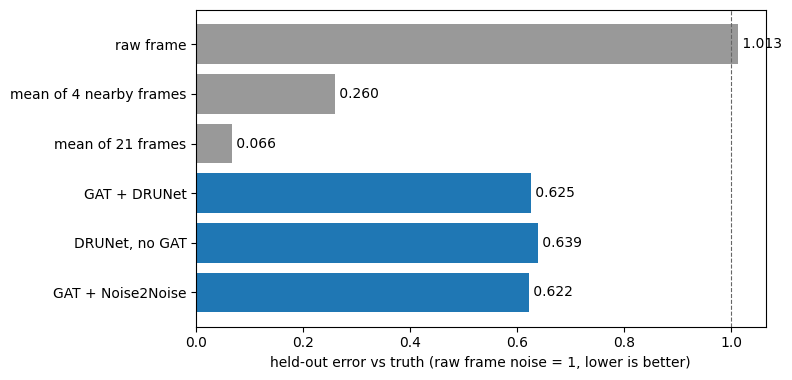

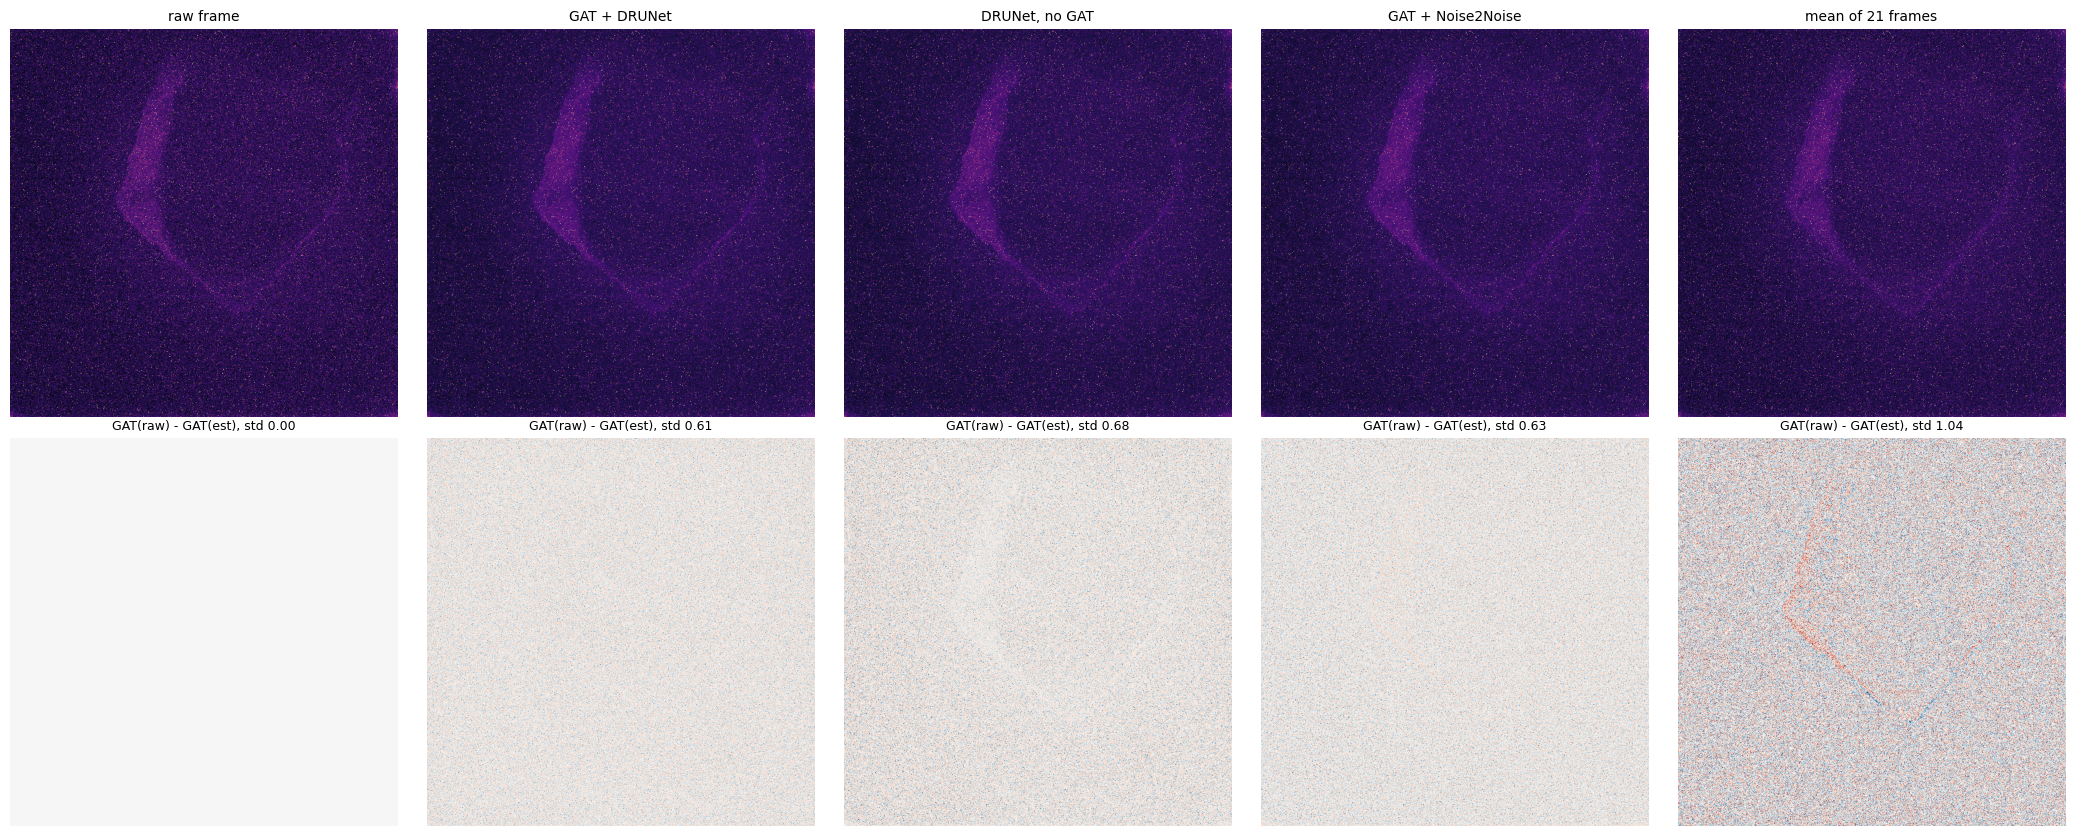

In [7]:
rois = dn.rois_for(cfg.get("rois"), CROP, BINNING)
scores, roi_ratio = {}, {}
raw_roi = dn.roi_means(counts[k], rois, mask)
for name, est in estimates.items():
    scores[name] = dn.heldout_error(est, counts, k, sigma, mask, tmask)
    r = dn.roi_means(est, rois, mask)
    roi_ratio[name] = {roi: r[roi] / raw_roi[roi] for roi in r}

print(f"{'method':32s} {'error':>7s} {'~frames':>8s}  ROI mean / raw")
for name, s in scores.items():
    eq = f"{1 / s:8.1f}" if s > 0 else "     inf"
    print(f"{name:32s} {s:7.3f} {eq}  " + ", ".join(f"{roi} {v:.3f}" for roi, v in roi_ratio[name].items()))

fig = dn.fig_scores(scores)
fig.savefig(out / "figures" / "scores.png", dpi=110)
plt.show()

shown = ["raw frame"] + list(denoisers) + [f"mean of {len(far)} frames"]
fig = dn.fig_compare([estimates[n] for n in shown], shown, rois=rois, residual_of=counts[k], sigma=sigma)
fig.savefig(out / "figures" / f"compare_frame{k:04d}.png", dpi=110)
plt.show()

for name in shown:
    dn.save_tif(out / f"frame{k:04d}_{name.replace(' ', '_').replace(',', '').replace('+', 'and')}.tif",
                estimates[name])

## 6 Whole run and the sum of all frames

Every frame with the best single-frame method, and the sum of all frames with GAT + DRUNet
(or BM3D). Noise2Noise was trained at single-frame noise levels, so it is not used on the sum.
The ROI means of raw and denoised frames should lie on top of each other: if they do not,
the method changes the photon budget and its images must not be used for rates. Expect a
small deficit where the true image varies strongly from pixel to pixel (the ToupTek's
dark-current speckle: ~1.5 % at 2x2 binning): smoothing in the square-root domain of the GAT
averages sqrt(x), and the square of a mean of square roots is below the mean.

best single-frame method: GAT + Noise2Noise
  frame 24/24, 91 s


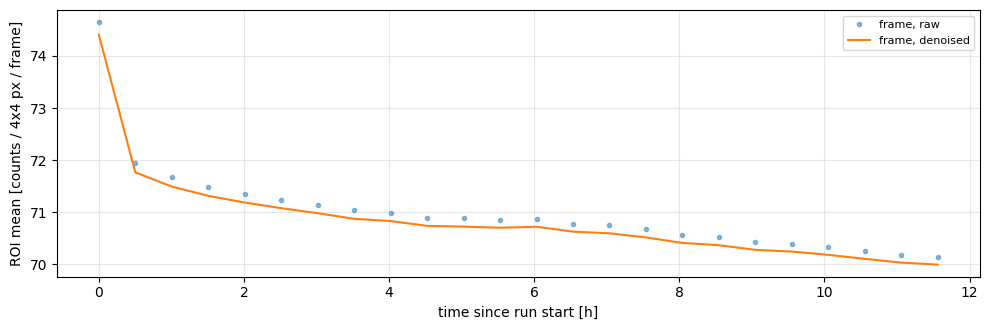

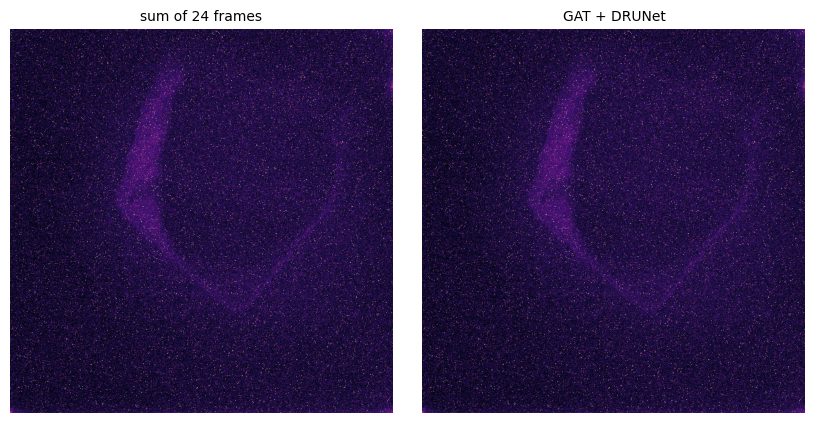

In [8]:
best = min(denoisers, key=lambda n: scores[n]) if denoisers else None
print("best single-frame method:", best)

den_stack = None
if DENOISE_ALL and best:
    den_stack = np.empty_like(counts, dtype=np.float32)
    t0 = time.time()
    for i in range(n_frames):
        den_stack[i] = denoisers[best](counts[i])
        print(f"\r  frame {i + 1}/{n_frames}, {time.time() - t0:.0f} s", end="")
    print()
    dn.save_tif(out / "denoised_frames_counts.tif", den_stack)
    raw_t = {roi: [] for roi in dn.roi_means(counts[0], rois, mask)}
    den_t = {roi: [] for roi in raw_t}
    for i in range(n_frames):
        for roi, v in dn.roi_means(counts[i], rois, mask).items():
            raw_t[roi].append(v)
        for roi, v in dn.roi_means(den_stack[i], rois, mask).items():
            den_t[roi].append(v)
    fig = dn.fig_timecourse(t_h, raw_t, den_t, unit=f"counts / {BINNING}x{BINNING} px / frame")
    fig.savefig(out / "figures" / "timecourse.png", dpi=110)
    plt.show()

sum_counts = counts.sum(0)
sum_name = next((n for n in ("GAT + DRUNet", "GAT + BM3D", "GAT + blur 1.5 px") if n in denoisers), None)
sum_den = None
if sum_name:
    sum_den = denoisers[sum_name](sum_counts, sigma * np.sqrt(n_frames), None)
    dn.save_tif(out / "sum_raw_counts.tif", sum_counts)
    dn.save_tif(out / "sum_denoised_counts.tif", sum_den)
    fig = dn.fig_compare([sum_counts, sum_den], [f"sum of {n_frames} frames", f"{sum_name}"], rois=rois)
    fig.savefig(out / "figures" / "sum.png", dpi=110)
    plt.show()

## 7 Summary

In [ ]:
summary = {
    "run": str(RUN_DIR), "detector": detector, "mode": MODE, "binning": BINNING, "crop": CROP,
    "frames": n_frames, "compared_frame": k,
    "noise_model": {key: v for key, v in model.items() if not key.startswith("bins")},
    "transient_fraction": float(tmask.mean()), "masked_pixel_fraction": float(mask.mean()),
    "median_counts_per_frame": level,
    "stabilised_std_overall": check["z_std_overall"],
    "stabilised_std_range": [min(check["z_std"]), max(check["z_std"])],
    "heldout_error": scores, "roi_mean_ratio": roi_ratio, "seconds": seconds,
    "best_method": best, "sum_method": sum_name,
    "settings": {"transient_sigma": TRANSIENT_SIGMA, "transient_dilate": list(TRANSIENT_DILATE),
                 "noisy_pixel_ratio": NOISY_PIXEL_RATIO, "n2n_steps": N2N_STEPS, "methods": METHODS},
}
dn.save_json(out / "summary.json", summary)

lines = [f"# E5 denoising - {RUN_DIR.name}", "",
         f"- noise model: {model['gain_adu_per_count']:.4g} ADU/count, offset {model['offset_adu']:.4g} ADU, "
         f"fit residual {model.get('fit_rel_residual_rms', 0):.1%}",
         f"- transients {tmask.mean():.2%} of pixel-frames, {mask.mean():.2%} of pixels left out",
         f"- GAT noise std {check['z_std_overall']:.3f} (range {min(check['z_std']):.2f}-{max(check['z_std']):.2f})",
         f"- best single-frame method: {best}", "",
         "| method | held-out error | ~frames averaged |", "|---|---|---|"]
lines += [f"| {n} | {s:.3f} | {1 / s:.1f} |" if s > 0 else f"| {n} | {s:.3f} | - |" for n, s in scores.items()]
lines += ["", "Figures in `figures/`, images in counts as float32 TIFF. Settings and numbers in `summary.json`."]
(out / "README.md").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

# E5 denoising - 2026-10-27_19-34-50_cress_h2o2

- noise model: 153.7 ADU/count, offset 484.1 ADU, fit residual 2.3%
- transients 4.65% of pixel-frames, 1.48% of pixels left out
- GAT noise std 1.009 (range 0.98-1.05)
- best single-frame method: GAT + Noise2Noise

| method | held-out error | ~frames averaged |
|---|---|---|
| raw frame | 1.036 | 1.0 |
| mean of 4 nearby frames | 0.268 | 3.7 |
| mean of 21 frames | 0.079 | 12.7 |
| GAT + DRUNet | 0.140 | 7.1 |
| DRUNet, no GAT | 0.168 | 5.9 |
| GAT + Noise2Noise | 0.138 | 7.3 |

Figures in `figures/`, images in counts as float32 TIFF. Settings and numbers in `summary.json`.
